# Sales Forecasting with Linear Regression

**Predicting monthly sales from Instagram ad spend**

**Business question:** *"If we spend more on Instagram ads, how much will sales increase?"*

This notebook fits a simple linear regression model to 8 years of monthly marketing data, evaluates it on held-out data, and quantifies the return per advertising dollar.

## 1. Setup & imports

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

## 2. Load the data

- **X = `instagram_ad_spend`** (USD/month, the input)
- **y = `sales`** (USD/month, the target)

In [2]:
df = pd.read_csv("data/sales_data.csv")
df.head()

,month,instagram_ad_spend,sales
0,2018-01,1810.89,125434.29
1,2018-02,3827.50,328455.06
2,2018-03,3061.98,258760.02
3,2018-04,2595.30,217105.68
4,2018-05,1046.07,98093.58


## 3. Explore the data

In [3]:
df.describe().round(2)

,instagram_ad_spend,sales
count,96.00,96.00
mean,2174.70,185779.54
std,1042.06,85862.06
min,519.33,38998.46
25%,1193.11,108536.95
50%,2190.52,183863.24
75%,3087.17,261839.66
max,3954.10,331447.30


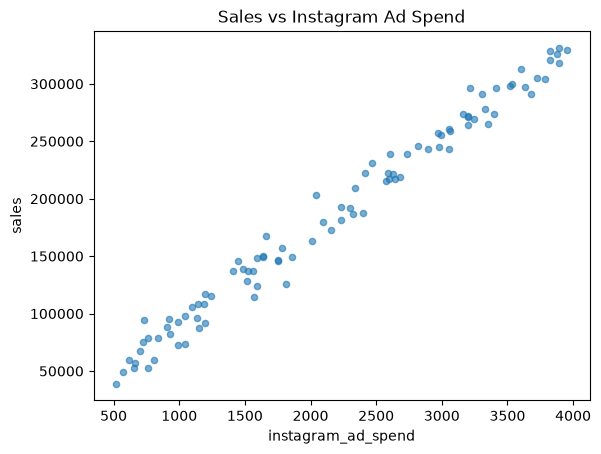

In [4]:
ax = df.plot.scatter(x="instagram_ad_spend", y="sales", alpha=0.6)
ax.set_title("Sales vs Instagram Ad Spend")
plt.savefig("output/regression_plot_raw.png", dpi=150)
plt.show()

There is a clear upward trend: higher ad spend tends to mean higher sales, so a linear model is a sensible choice.

## 4. Split into training and test sets

We hold out 20% of the data so we can measure performance on **unseen** records.

In [5]:
X = df[["instagram_ad_spend"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")

Training rows: 76 | Test rows: 20


## 5. Fit the linear regression model

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intercept: {model.intercept_:,.2f}")
print(f"Slope:     {model.coef_[0]:,.2f}  <-- sales gained per $1 of ad spend")
print("")
print(f"Model: sales = {model.intercept_:,.2f} + ({model.coef_[0]:,.2f} * instagram_ad_spend)")

Intercept: 7,521.15
Slope:     82.15  <-- sales gained per $1 of ad spend

Model: sales = 7,521.15 + (82.15 * instagram_ad_spend)


## 6. Evaluate on the test set

In [7]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

metrics = pd.DataFrame(
    {"R2": [r2], "MAE (USD)": [mae], "RMSE (USD)": [rmse]}
).round(2)
metrics

,R2,MAE (USD),RMSE (USD)
0,0.99,7931.87,10423.62


**What these mean:**

- **R² = 0.988** — ad spend explains ~99% of the variation in sales in this simulated dataset.
- **MAE ≈ $7,900** — predictions miss by about $7.9k on average.
- **RMSE ≈ $10,400** — a bit higher than MAE because RMSE penalizes large errors more.

## 7. Answer the business question

The **slope (+82.15)** is the headline number: for every extra $1 spent on Instagram ads, sales grow by about **$82 on average**. Below, we forecast sales for several budgets.

In [8]:
budgets = [1500, 2500, 3500, 5000]
scenario = pd.DataFrame({"instagram_ad_spend": budgets})
scenario["predicted_sales"] = model.predict(scenario)
scenario.round(2)

,instagram_ad_spend,predicted_sales
0,1500,130739.33
1,2500,212884.79
2,3500,295030.24
3,5000,418248.42


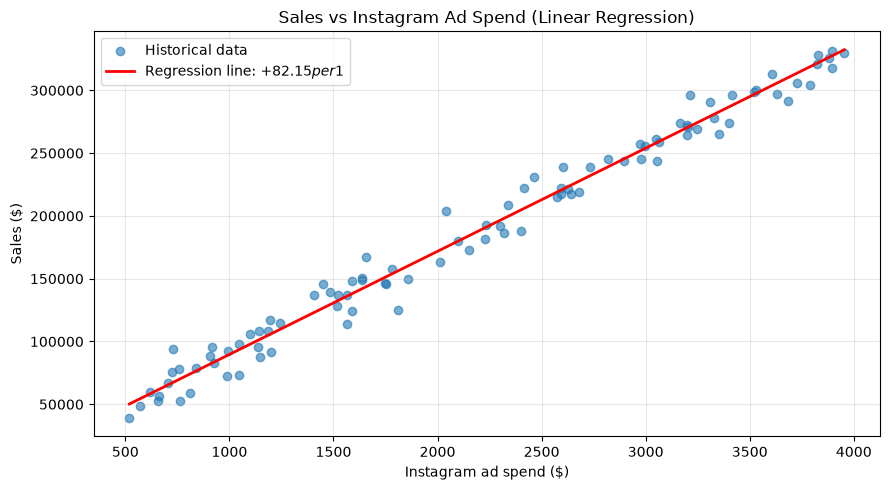

In [9]:
plt.figure(figsize=(9, 5))
plt.scatter(df["instagram_ad_spend"], df["sales"], alpha=0.6, label="Historical data")
line_x = pd.DataFrame({"instagram_ad_spend": [df["instagram_ad_spend"].min(), df["instagram_ad_spend"].max()]})
plt.plot(line_x, model.predict(line_x), color="red", linewidth=2, label="Regression line: +$82.15 per $1")
plt.xlabel("Instagram ad spend ($)")
plt.ylabel("Sales ($)")
plt.title("Sales vs Instagram Ad Spend (Linear Regression)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("output/regression_plot.png", dpi=150)
plt.show()

## 8. Conclusion & key takeaways

1. **Linear regression converts ad spend into a budget decision.** The fitted line says every $1 of Instagram spend returns ~$82 in sales.
2. **The model forecasts any budget.** Enter any ad spend and get an expected sales figure instantly.
3. **Evaluation matters.** We judge the model on the 20% of records it never trained on (R² = 0.988, MAE ≈ $7.9k).

**Next steps:** add more channels (TV, email) for multiple regression, compare with Ridge/Random Forest, cross-validate, and export the model with `joblib` for a live prediction app.